# can-bus-ids

In [ ]:
-8import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

print("Environnement CAN IDS prêt.")

Environnement CAN IDS prêt.


In [ ]:
df_rpm = pd.read_csv('/content/RPM_dataset.csv', header=None, on_bad_lines='skip')
df_gear = pd.read_csv('/content/gear_dataset.csv', header=None, on_bad_lines='skip')
df_dos = pd.read_csv('/content/DoS_dataset.csv', header=None, on_bad_lines='skip')
df_fuzzy = pd.read_csv('/content/Fuzzy_dataset.csv', header=None, on_bad_lines='skip')

print("RPM dataset shape:", df_rpm.shape)
print("Gear dataset shape:", df_gear.shape)
print("DoS dataset shape:", df_dos.shape)
print("Fuzzy dataset shape:", df_fuzzy.shape)

RPM dataset shape: (546037, 12)
Gear dataset shape: (566318, 12)
DoS dataset shape: (545918, 12)
Fuzzy dataset shape: (89921, 12)


/tmp/ipykernel_1446/4006929363.py:4: DtypeWarning: Columns (6,9,11) have mixed types. Specify dtype option on import or set low_memory=False.
  df_fuzzy = pd.read_csv('/content/Fuzzy_dataset.csv', header=None, on_bad_lines='skip')


# Vérifier la structure des datasets

In [ ]:
datasets = {
    "RPM": df_rpm,
    "Gear": df_gear,
    "DoS": df_dos,
    "Fuzzy": df_fuzzy
}

for name, df in datasets.items():
    print(f"\n--- {name} ---")
    print("Shape:", df.shape)
    print(df.head(3))
    print("Types:", df.dtypes.tolist())


--- RPM ---
Shape: (541461, 12)
      timestamp can_id  dlc data_0 data_1 data_2 data_3 data_4 data_5 data_6  \
0  1.478191e+09   0316    8     05     22     68     09     22     20     00   
1  1.478191e+09   018f    8     fe     3b     00     00     00     3c     00   
2  1.478191e+09   0260    8     19     22     22     30     ff     8f     6e   

  data_7 flag  
0     75    R  
1     00    R  
2     3f    R  
Types: [dtype('float64'), dtype('O'), dtype('int64'), dtype('O'), dtype('O'), dtype('O'), dtype('O'), dtype('O'), dtype('O'), dtype('O'), dtype('O'), dtype('O')]

--- Gear ---
Shape: (561408, 12)
      timestamp can_id  dlc data_0 data_1 data_2 data_3 data_4 data_5 data_6  \
0  1.478193e+09   0140  8.0     00     00     00     00     10     29     2a   
1  1.478193e+09   02c0  8.0     15     00     00     00     00     00     00   
2  1.478193e+09   0350  8.0     05     20     44     68     77     00     00   

  data_7 flag  
0     24    R  
1     00    R  
2     7e    R  
T

In [31]:
df_gear.head()

,timestamp,can_id,dlc,data_0,data_1,data_2,data_3,data_4,data_5,data_6,data_7,flag
0,1.478193e+09,0140,8.0,00,00,00,00,10,29,2a,24,R
1,1.478193e+09,02c0,8.0,15,00,00,00,00,00,00,00,R
2,1.478193e+09,0350,8.0,05,20,44,68,77,00,00,7e,R
3,1.478193e+09,0370,8.0,00,20,00,00,00,00,00,00,R
4,1.478193e+09,043f,8.0,10,40,60,ff,78,c4,08,00,R


In [32]:
datasets = {
    "RPM": df_rpm,
    "Gear": df_gear,
    "DoS": df_dos,
    "Fuzzy": df_fuzzy
}

for name, df in datasets.items():
    print(f"\n===== {name} =====")
    print("Dimensions :", df.shape)
    print("Valeurs manquantes :", df.isnull().sum().sum())
    print("Lignes dupliquées :", df.duplicated().sum())
    print("Types des colonnes :")
    print(df.dtypes)
    display(df.head())


===== RPM =====
Dimensions : (541461, 12)
Valeurs manquantes : 0
Lignes dupliquées : 0
Types des colonnes :
timestamp    float64
can_id        object
dlc            int64
data_0        object
data_1        object
data_2        object
data_3        object
data_4        object
data_5        object
data_6        object
data_7        object
flag          object
dtype: object


,timestamp,can_id,dlc,data_0,data_1,data_2,data_3,data_4,data_5,data_6,data_7,flag
0,1.478191e+09,0316,8,05,22,68,09,22,20,00,75,R
1,1.478191e+09,018f,8,fe,3b,00,00,00,3c,00,00,R
2,1.478191e+09,0260,8,19,22,22,30,ff,8f,6e,3f,R
3,1.478191e+09,02a0,8,60,00,83,1d,96,02,bd,00,R
4,1.478191e+09,0329,8,dc,b8,7e,14,11,20,00,14,R



===== Gear =====
Dimensions : (561408, 12)
Valeurs manquantes : 0
Lignes dupliquées : 0
Types des colonnes :
timestamp    float64
can_id        object
dlc          float64
data_0        object
data_1        object
data_2        object
data_3        object
data_4        object
data_5        object
data_6        object
data_7        object
flag          object
dtype: object


,timestamp,can_id,dlc,data_0,data_1,data_2,data_3,data_4,data_5,data_6,data_7,flag
0,1.478193e+09,0140,8.0,00,00,00,00,10,29,2a,24,R
1,1.478193e+09,02c0,8.0,15,00,00,00,00,00,00,00,R
2,1.478193e+09,0350,8.0,05,20,44,68,77,00,00,7e,R
3,1.478193e+09,0370,8.0,00,20,00,00,00,00,00,00,R
4,1.478193e+09,043f,8.0,10,40,60,ff,78,c4,08,00,R



===== DoS =====
Dimensions : (541685, 12)
Valeurs manquantes : 0
Lignes dupliquées : 0
Types des colonnes :
timestamp    float64
can_id        object
dlc            int64
data_0        object
data_1        object
data_2        object
data_3        object
data_4        object
data_5        object
data_6        object
data_7        object
flag          object
dtype: object


,timestamp,can_id,dlc,data_0,data_1,data_2,data_3,data_4,data_5,data_6,data_7,flag
0,1.478198e+09,0316,8,05,21,68,09,21,21,00,6f,R
1,1.478198e+09,018f,8,fe,5b,00,00,00,3c,00,00,R
2,1.478198e+09,0260,8,19,21,22,30,08,8e,6d,3a,R
3,1.478198e+09,02a0,8,64,00,9a,1d,97,02,bd,00,R
4,1.478198e+09,0329,8,40,bb,7f,14,11,20,00,14,R



===== Fuzzy =====
Dimensions : (85681, 12)
Valeurs manquantes : 10479
Lignes dupliquées : 0
Types des colonnes :
timestamp    float64
can_id        object
dlc            int64
data_0        object
data_1        object
data_2        object
data_3        object
data_4        object
data_5        object
data_6        object
data_7        object
flag          object
dtype: object


,timestamp,can_id,dlc,data_0,data_1,data_2,data_3,data_4,data_5,data_6,data_7,flag
0,1.478196e+09,0545,8,d8,00,00,8a,00,00,00,00,R
2,1.478196e+09,0002,8,00,00,00,00,00,01,07,15,R
3,1.478196e+09,0153,8,00,21,10,ff,00,ff,00,00,R
4,1.478196e+09,0130,8,19,80,00,ff,fe,7f,07,60,R
5,1.478196e+09,0131,8,17,80,00,00,65,7f,07,9f,R


In [33]:
import pandas as pd
import numpy as np

columns = [
    "timestamp", "can_id", "dlc",
    "data_0", "data_1", "data_2", "data_3",
    "data_4", "data_5", "data_6", "data_7",
    "label"
]

def clean_can_dataset(df):
    df = df.copy()

    # Uniformiser les noms de colonnes
    df.columns = columns

    # Supprimer les lignes entièrement vides
    df = df.dropna(how="all")

    # Convertir le timestamp
    df["timestamp"] = pd.to_numeric(
        df["timestamp"], errors="coerce"
    )

    # Normaliser le CAN ID en texte
    df["can_id"] = df["can_id"].astype(str).str.strip()

    # Convertir les caractéristiques numériques
    numeric_cols = [
        "dlc", "data_0", "data_1", "data_2",
        "data_3", "data_4", "data_5", "data_6", "data_7"
    ]

    for col in numeric_cols:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    # Uniformiser les étiquettes
    df["label"] = (
        df["label"].astype(str).str.strip().str.upper()
    )

    # Supprimer les lignes avec champs indispensables invalides
    df = df.dropna(
        subset=["timestamp", "can_id", "dlc", "label"]
    )

    # Conserver uniquement les DLC valides
    df = df[df["dlc"].between(0, 8)]

    # Les octets présents doivent être compris entre 0 et 255
    data_cols = [f"data_{i}" for i in range(8)]
    invalid_bytes = (
        (df[data_cols] < 0) | (df[data_cols] > 255)
    ).any(axis=1)

    df = df[~invalid_bytes]

    return df.reset_index(drop=True)


df_rpm_clean = clean_can_dataset(df_rpm)
df_gear_clean = clean_can_dataset(df_gear)
df_dos_clean = clean_can_dataset(df_dos)
df_fuzzy_clean = clean_can_dataset(df_fuzzy)

for name, df in {
    "RPM": df_rpm_clean,
    "Gear": df_gear_clean,
    "DoS": df_dos_clean,
    "Fuzzy": df_fuzzy_clean
}.items():
    print(name, ":", df.shape)

RPM : (541461, 12)
Gear : (561408, 12)
DoS : (541685, 12)
Fuzzy : (62095, 12)


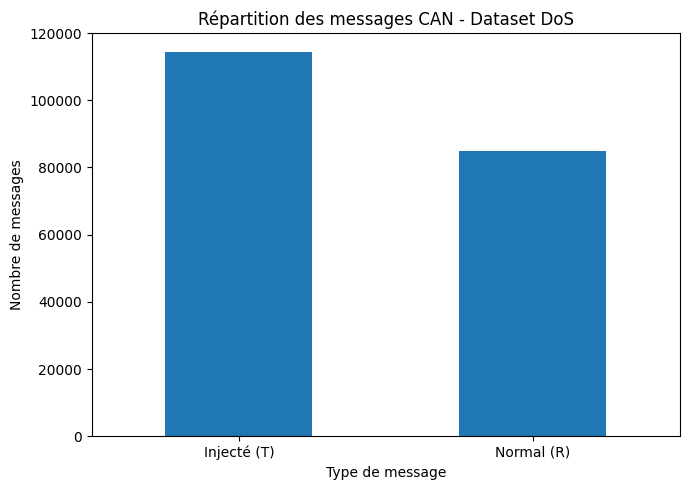

In [ ]:
# Répartition des labels du dataset DoS
label_counts = y_dos.map({
    0: "Normal (R)",
    1: "Injecté (T)"
}).value_counts()

plt.figure(figsize=(7, 5))
label_counts.plot(kind="bar")
plt.title("Répartition des messages CAN - Dataset DoS")
plt.xlabel("Type de message")
plt.ylabel("Nombre de messages")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# merge the 4 db

In [34]:
import pandas as pd

# Ajouter une colonne pour identifier le scénario d'origine
df_rpm_clean["scenario"] = "RPM"
df_gear_clean["scenario"] = "Gear"
df_dos_clean["scenario"] = "DoS"
df_fuzzy_clean["scenario"] = "Fuzzy"

# Fusionner les quatre datasets verticalement
df_merged = pd.concat(
    [
        df_rpm_clean,
        df_gear_clean,
        df_dos_clean,
        df_fuzzy_clean
    ],
    ignore_index=True
)

print("Dimensions du dataset fusionné :", df_merged.shape)
display(df_merged.head())

Dimensions du dataset fusionné : (1706649, 13)


,timestamp,can_id,dlc,data_0,data_1,data_2,data_3,data_4,data_5,data_6,data_7,label,scenario
0,1.478191e+09,0316,8.0,5.0,22.0,68.0,9.0,22.0,20.0,0.0,75.0,R,RPM
1,1.478191e+09,018f,8.0,NaN,NaN,0.0,0.0,0.0,NaN,0.0,0.0,R,RPM
2,1.478191e+09,0260,8.0,19.0,22.0,22.0,30.0,NaN,NaN,NaN,NaN,R,RPM
3,1.478191e+09,02a0,8.0,60.0,0.0,83.0,NaN,96.0,2.0,NaN,0.0,R,RPM
4,1.478191e+09,0329,8.0,NaN,NaN,NaN,14.0,11.0,20.0,0.0,14.0,R,RPM


In [35]:
# Nombre de lignes par scénario
print(df_merged["scenario"].value_counts())

# Distribution des labels par scénario
print(pd.crosstab(
    df_merged["scenario"],
    df_merged["label"]
))

# Valeurs manquantes
print("Valeurs manquantes :", df_merged.isnull().sum().sum())

# Doublons
print("Lignes dupliquées :", df_merged.duplicated().sum())


scenario
Gear     561408
DoS      541685
RPM      541461
Fuzzy     62095
Name: count, dtype: int64
label          R       T
scenario                
DoS       427336  114349
Fuzzy      52508    9587
Gear      462039   99369
RPM       445432   96029
Valeurs manquantes : 2759055
Lignes dupliquées : 0


In [44]:
# Nombre et pourcentage de valeurs manquantes par colonne
missing = pd.DataFrame({
    "Valeurs_manquantes": df_merged.isna().sum(),
    "Pourcentage_%": (
        df_merged.isna().mean() * 100
    ).round(2)
})

display(
    missing.sort_values(
        "Pourcentage_%",
        ascending=False
    )
)

,Valeurs_manquantes,Pourcentage_%
data_3,575094,33.70
data_5,429737,25.18
data_7,420755,24.65
data_0,363314,21.29
data_4,329591,19.31
data_6,292400,17.13
data_2,180303,10.56
data_1,167861,9.84
timestamp,0,0.00
can_id,0,0.00


In [42]:
print("Dimensions :", df_merged.shape)

print("\nTypes des colonnes :")
print(df_merged.dtypes)

print("\nExemples de données :")
display(df_merged.head(10))

Dimensions : (1706649, 14)

Types des colonnes :
timestamp    float64
can_id        object
dlc          float64
data_0       float64
data_1       float64
data_2       float64
data_3       float64
data_4       float64
data_5       float64
data_6       float64
data_7       float64
label         object
scenario      object
target         int64
dtype: object

Exemples de données :


,timestamp,can_id,dlc,data_0,data_1,data_2,data_3,data_4,data_5,data_6,data_7,label,scenario,target
0,1.478191e+09,0316,8.0,5.0,22.0,68.0,9.0,22.0,20.0,0.0,75.0,R,RPM,0
1,1.478191e+09,018f,8.0,NaN,NaN,0.0,0.0,0.0,NaN,0.0,0.0,R,RPM,0
2,1.478191e+09,0260,8.0,19.0,22.0,22.0,30.0,NaN,NaN,NaN,NaN,R,RPM,0
3,1.478191e+09,02a0,8.0,60.0,0.0,83.0,NaN,96.0,2.0,NaN,0.0,R,RPM,0
4,1.478191e+09,0329,8.0,NaN,NaN,NaN,14.0,11.0,20.0,0.0,14.0,R,RPM,0
5,1.478191e+09,0545,8.0,NaN,0.0,0.0,83.0,0.0,0.0,0.0,0.0,R,RPM,0
6,1.478191e+09,02c0,8.0,15.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,R,RPM,0
7,1.478191e+09,0002,8.0,0.0,0.0,0.0,0.0,0.0,7.0,9.0,6.0,R,RPM,0
8,1.478191e+09,0153,8.0,0.0,21.0,10.0,NaN,0.0,NaN,0.0,0.0,R,RPM,0
9,1.478191e+09,0130,8.0,3.0,80.0,0.0,NaN,NaN,80.0,9.0,NaN,R,RPM,0


In [43]:
for name, df in {
    "RPM": df_rpm_clean,
    "Gear": df_gear_clean,
    "DoS": df_dos_clean,
    "Fuzzy": df_fuzzy_clean
}.items():
    print(f"\n{name} — {df.shape}")
    print(df.columns.tolist())
    print("Valeurs manquantes :", df.isna().sum().sum())


RPM — (541461, 13)
['timestamp', 'can_id', 'dlc', 'data_0', 'data_1', 'data_2', 'data_3', 'data_4', 'data_5', 'data_6', 'data_7', 'label', 'scenario']
Valeurs manquantes : 905137

Gear — (561408, 13)
['timestamp', 'can_id', 'dlc', 'data_0', 'data_1', 'data_2', 'data_3', 'data_4', 'data_5', 'data_6', 'data_7', 'label', 'scenario']
Valeurs manquantes : 972357

DoS — (541685, 13)
['timestamp', 'can_id', 'dlc', 'data_0', 'data_1', 'data_2', 'data_3', 'data_4', 'data_5', 'data_6', 'data_7', 'label', 'scenario']
Valeurs manquantes : 747269

Fuzzy — (62095, 13)
['timestamp', 'can_id', 'dlc', 'data_0', 'data_1', 'data_2', 'data_3', 'data_4', 'data_5', 'data_6', 'data_7', 'label', 'scenario']
Valeurs manquantes : 134292


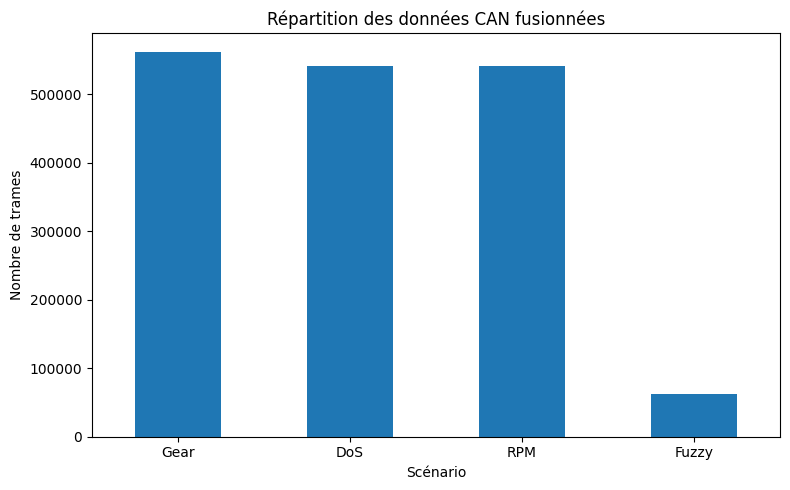

In [36]:
import matplotlib.pyplot as plt

df_merged["scenario"].value_counts().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Répartition des données CAN fusionnées")
plt.xlabel("Scénario")
plt.ylabel("Nombre de trames")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [37]:
df_merged.to_csv(
    "/content/CAN_merged_dataset.csv",
    index=False
)

print("Dataset enregistré : /content/CAN_merged_dataset.csv")

Dataset enregistré : /content/CAN_merged_dataset.csv


In [38]:
import pandas as pd
import numpy as np

# Vérifier les labels présents
print(df_merged["label"].value_counts(dropna=False))

# Convertir les labels en deux classes
# Adapter ce mapping aux labels réellement présents
df_merged["label"] = (
    df_merged["label"].astype(str).str.strip().str.upper()
)

df_merged["target"] = df_merged["label"].map({
    "R": 0,        # Normal
    "T": 1,        # Attaque
    "NORMAL": 0,
    "ATTACK": 1,
    "ATTAQUE": 1
})

# Vérifier les labels non reconnus
print("Labels non reconnus :",
      df_merged.loc[df_merged["target"].isna(), "label"].unique())

# Garder les lignes avec une cible connue
df_ml = df_merged.dropna(subset=["target"]).copy()
df_ml["target"] = df_ml["target"].astype(int)

# Construire X et y
# Les colonnes textuelles ne peuvent pas être utilisées directement
X = df_ml.drop(columns=["label", "target", "scenario"])
y = df_ml["target"]

# Convertir les colonnes numériques
X = X.apply(pd.to_numeric, errors="coerce")

# Remplacer les valeurs infinies par NaN
X = X.replace([np.inf, -np.inf], np.nan)

# Remplacer les valeurs manquantes par la médiane
X = X.fillna(X.median())

print("Dimensions de X :", X.shape)
print("Répartition des classes :")
print(y.value_counts())

label
R    1387315
T     319334
Name: count, dtype: int64
Labels non reconnus : []
Dimensions de X : (1706649, 11)
Répartition des classes :
target
0    1387315
1     319334
Name: count, dtype: int64


In [39]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Train :", X_train.shape)
print("Test  :", X_test.shape)

Train : (1365319, 11)
Test  : (341330, 11)


In [40]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Entraînement terminé !")

Entraînement terminé !


Accuracy : 1.0

Rapport de classification :
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00    277463
     Attaque       1.00      1.00      1.00     63867

    accuracy                           1.00    341330
   macro avg       1.00      1.00      1.00    341330
weighted avg       1.00      1.00      1.00    341330



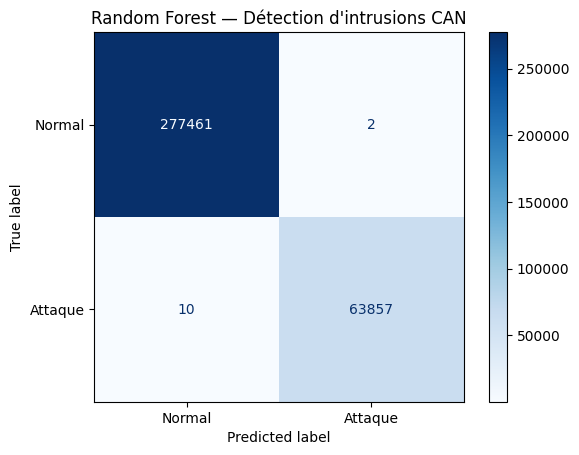

In [41]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

y_pred = rf_model.predict(X_test)

print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("\nRapport de classification :")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Normal", "Attaque"],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Attaque"]
).plot(cmap="Blues", values_format="d")

plt.title("Random Forest — Détection d'intrusions CAN")
plt.show()